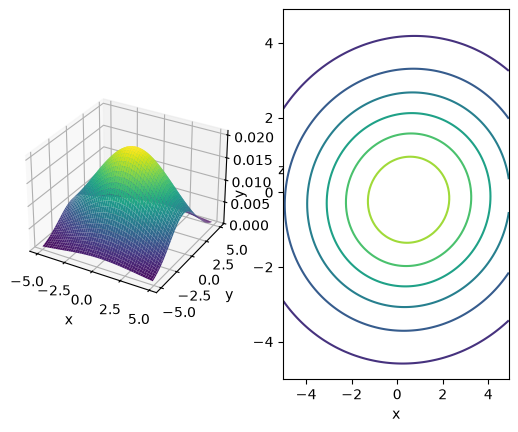

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


# 다변량 정규분포
def multivariate_normal(x, mu, cov):
    det = np.linalg.det(cov)
    inv = np.linalg.inv(cov)
    D = len(x)
    z = 1 / np.sqrt((2 * np.pi) ** D * det)
    y = z * np.exp((x - mu).T @ inv @ (x - mu) / -2.0)
    return y

# 표본 성분이 2개이고, 각각의 평균이 0.5, -0.2
mu = np.array([0.5, -0.2])

# 공분산 행렬의
# 대각성분 (분산): 표본의 해당 성분의 분산
# 비대각성분 (공분산): i, j의 성분이 함께 움직이는 정도. 양수: 비례, 음수: 반비례, 0: 선형관계 없음
cov = np.array([[1., 0.3], 
                [0.3, 5]])


xs = ys = np.arange(-5, 5, 0.1)
X, Y = np.meshgrid(xs, ys)
Z = np.zeros_like(X)

for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = np.array([X[i, j], Y[i, j]])
        Z[i, j] = multivariate_normal(x, mu, cov)

# 그래프 그리기
fig = plt.figure()
ax1 = fig.add_subplot(1, 2, 1, projection='3d') # [1, 2] 영역의 1번 서브캔버스
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('z')
ax1.plot_surface(X, Y, Z, cmap='viridis')

ax2 = fig.add_subplot(1, 2, 2) # [1, 2] 영역의 2번 서브캔버스
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.contour(X, Y, Z)
plt.show()